In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル / ホスト環境で実行中。ルート:", repo_root)


💻 ローカル / ホスト環境で実行中。ルート: /home/student/Documents/GitHub/study-mikanos


# 7.7 割り込みハンドラの高速化 (`Fast Interrupt Handling: Top Half / Bottom Half`)

本節では、名著『ゼロからのOS自作入門』（内田公太 著、マイナビ出版）の第7章「割り込みとFIFO」7.7節および対応タグ **`osbook_day07b`** に基づき、前節まで構築した「モノリシック（一体型）割り込みハンドラ」が抱える致命的なボトルネックを解明し、OS設計における金字塔的アーキテクチャである **「Top Half（トップハーフ / Hardirq）」と「Bottom Half（ボトムハーフ / Softirq / 遅延処理）」の分離** を導入します。

> [!IMPORTANT]
> **本節の学習目標 (Learning Objectives)**:
> 1. **モノリシック割り込みハンドラの限界の理解**: なぜピクセル描画のような重い処理を割り込みハンドラ内で直接実行してはいけないのか、x86-64 の多重割り込み抑止機構（`IF=0`）と「割り込み遅延（*Interrupt Latency*）」の爆発的増大、パケットドロップの数理メカニズムを解明する。
> 2. **Top Half と Bottom Half の設計原則**: 最小限のハードウェア応答（キューイング＋EOI）のみを行う Top Half と、割り込み許可状態（`IF=1`）で動作するイベントループ（Bottom Half）の役割分担を習得する。
> 3. **プリエンプション（割り込みの割り込み）による低遅延化**: 重い描画処理を実行中であっても、新たなハードウェア割り込みが瞬時に介入してイベントを取りこぼさないメカニズムを理解する。
> 4. **MikanOS における実装差分 (`osbook_day07a` $\to$ `osbook_day07b`)**: `struct Message` と `ArrayQueue<Message>` による非同期イベント通知モデルを C++20 で実装・検証する。


## 7.7.1 モノリシック割り込みハンドラの抱える根本的ボトルネック

### 1. 前節 `osbook_day07a` の実装と課題

前節（7.6節）で完成させた割り込みハンドラ `IntHandlerXHCI` は次のように記述されていました：

```cpp
// osbook_day07a / kernel/main.cpp
__attribute__((interrupt))
void IntHandlerXHCI(InterruptFrame* frame) {
  while (xhc->PrimaryEventRing()->HasFront()) {
    if (auto err = ProcessEvent(*xhc)) {
      Log(kError, "Error while ProcessEvent: %s\n", err.Name());
    }
  }
  NotifyEndOfInterrupt();
}
```

この実装では、USB マウスが動くたびに以下の処理が**割り込みハンドラの中で直接**実行されます：
1. `ProcessEvent(*xhc)` の実行
2. USB HID マウスパケットの解析 $\to$ `MouseObserver(dx, dy)` の呼び出し
3. マウスカーソルの移動計算 $\to$ **背景色による以前のカーソル領域の消去描画**
4. **新しい座標における 16×24 ピクセルの矢印カーソル描画**（$16 \times 24 = 384$ ピクセルへの VRAM 書き込み）

一見すると「イベントが起きたらその場で画面を更新する」という直感的で素朴な実装に見えます。しかし、これには**OSとして致命的な欠陥**が潜んでいます。


### 2. 多重割り込み抑止 (`IF=0`) とピクセル描画コストの衝突

x86-64 アーキテクチャにおいて、割り込みゲート（*Interrupt Gate*）を経由して割り込みハンドラに突入すると、CPU ハードウェアは自動的に `RFLAGS` レジスタの **IF (Interrupt Flag)** を `0` にクリアします（CLI 状態）。

```
        CPU Core Status: IF = 0 (Interrupts DISABLED)
   |<---------------- Handler Execution Time T_handler ---------------->|
---|====================================================================|---> Time
   ^                                                                    ^
   |-- 割り込み突入 (IF=0)                                              |-- IRETQ 復帰 (IF=1)
       [この間、他のあらゆるハードウェア割り込みは CPU に無視・保留される！]
```

- **描画コストのオーダー**:
  解像度 $800 \times 600$ や $1024 \times 768$ のフレームバッファに対するピクセル描画は、数百〜数千クロックサイクル、重いスクロールや全画面再描画では数万〜数百万クロックサイクル（数十ミリ秒）に達します。
- **割り込み遅延 (*Interrupt Latency*) の増大**:
  ハンドラ実行中に発生した他の割り込み（例: タイマ割り込み、キーボード割り込み、LAN コントローラのパケット受信割り込み等）は、ハンドラが `iretq` を実行して `IF=1` に戻るまで一切処理されません。
- **ハードウェアバッファのオーバーフローとパケットドロップ**:
  マウスを素早く振ると、USB コントローラは 1ms (1000Hz) ごとに連続してパケットを送り込んできます。ハンドラが前のイベントの描画で詰まっていると、コントローラの内部 FIFO（Event Ring や PCIe バッファ）が瞬時に溢れ、**マウスイベントのドロップ（カーソルのカクつきや飛び）** が発生します。


✅ 生成完了: 7/result/fig7_13_monolithic_vs_split_interrupt_timeline.png


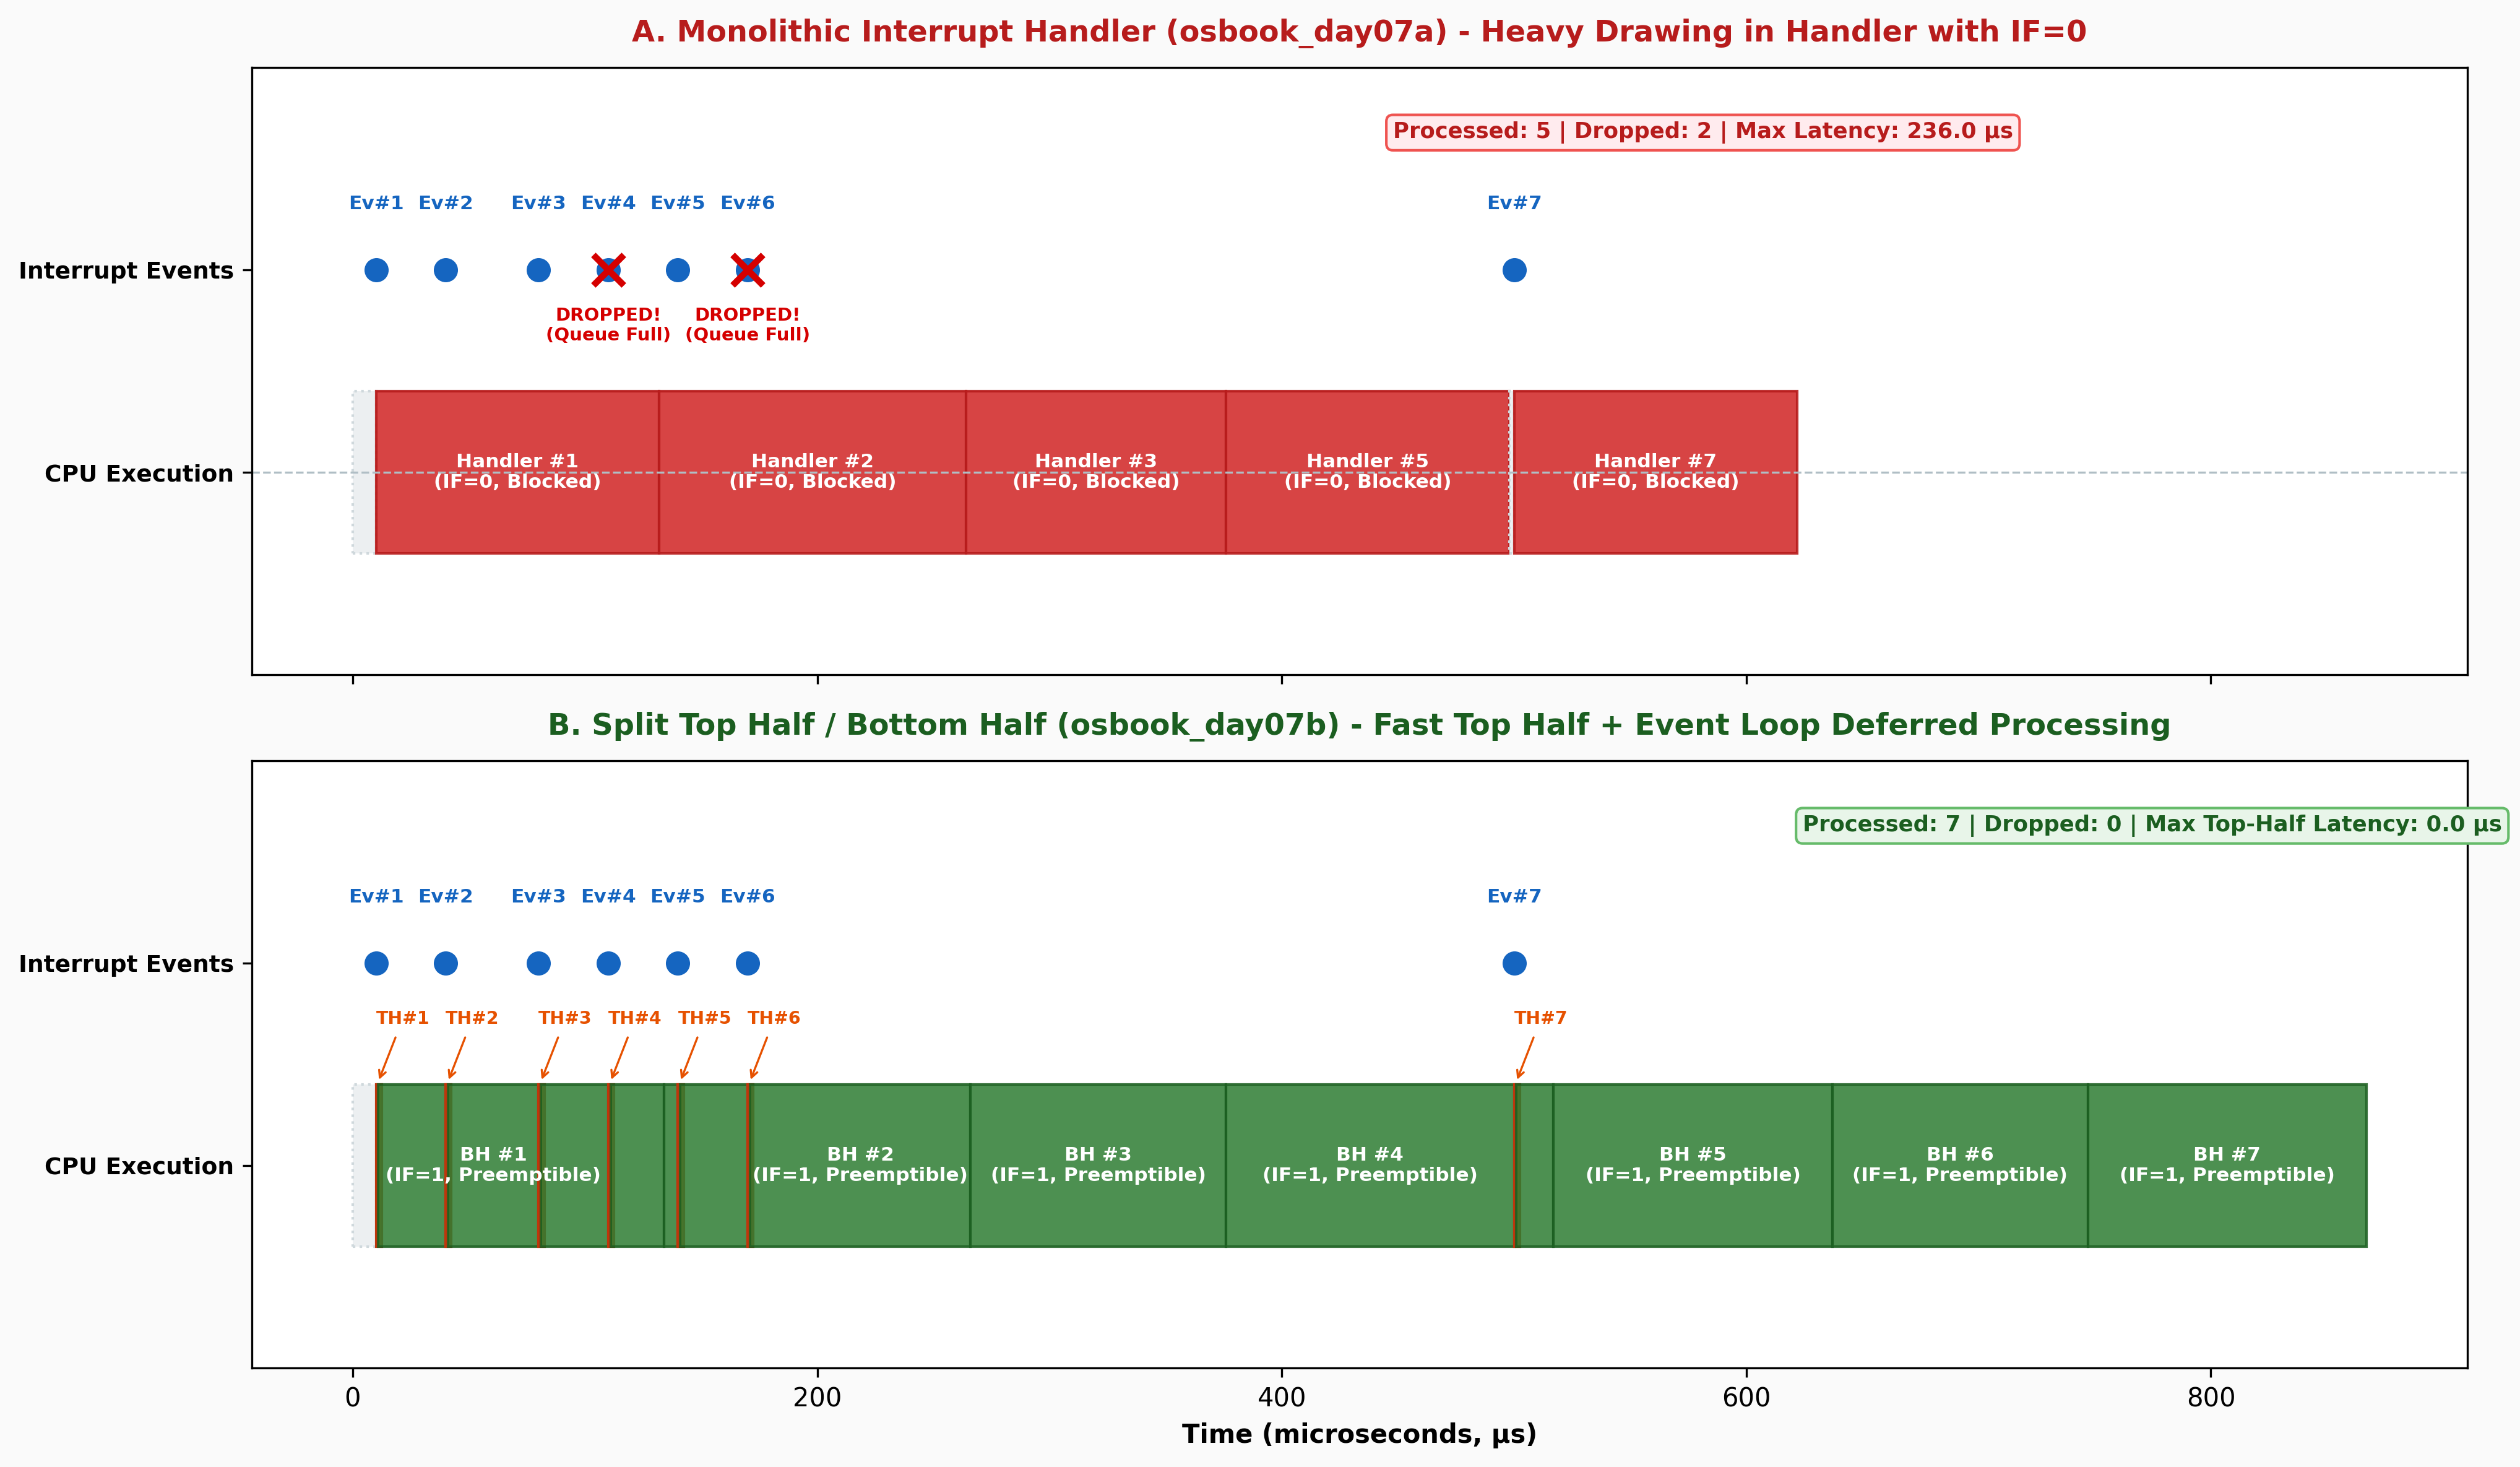

In [2]:
import matplotlib.pyplot as plt
from common import (
    FastInterruptEvent,
    simulate_monolithic_interrupts,
    simulate_split_interrupts,
    plot_monolithic_vs_split_interrupt_timeline,
)

# Figure 7.13: モノリシック一体型 vs 分割型の時系列比較プロット
fig_path = plot_monolithic_vs_split_interrupt_timeline("7/result/fig7_13_monolithic_vs_split_interrupt_timeline.png")
print("✅ 生成完了:", fig_path)

# ノートブック内に高解像度表示
from IPython.display import Image, display
display(Image(fig_path))


## 7.7.2 OS設計の金字塔「Top Half / Bottom Half」アーキテクチャ

この問題を解決するために、モダン OS（Linux, Windows, macOS, 各種リアルタイムOS）はすべて **「割り込み処理の2段階分割」** を採用しています。

```mermaid
flowchart TD
    subgraph TopHalf["Top Half (トップハーフ / Hardirq)"]
        A[ハードウェア割り込み発生] --> B[CPU突入: IF=0]
        B --> C[ハードウェア状態の確認・最小処理]
        C --> D["イベントをキュー (ArrayQueue) に Push"]
        D --> E[NotifyEndOfInterrupt EOI 発行]
        E --> F["IRETQ 復帰 (IF=1)"]
    end

    subgraph BottomHalf["Bottom Half (ボトムハーフ / Softirq / Event Loop)"]
        G[メインループ / KernelMain] --> H{"キューにイベントがあるか？"}
        H -- Yes --> I[キューから Pop]
        I --> J["重い処理の実行 (ProcessEvent / 画面描画)"]
        J --> G
        H -- No --> K["CPU省電力休止 (HLT)"]
        K --> G
    end

    D -.->|非同期キューイング| H

    style TopHalf fill:#FFF3E0,stroke:#E65100,stroke-width:2px
    style BottomHalf fill:#E8F5E9,stroke:#2E7D32,stroke-width:2px
```

### 1. Top Half（トップハーフ / Hardirq）の責務
- **実行コンテキスト**: 割り込みコンテキスト（`IF=0`、多重割り込み抑止中）
- **許容実行時間**: **数ナノ秒〜1マイクロ秒未満（極小）**
- **行うべき作業**:
  1. ハードウェアの割り込み要因レジスタの最小限の確認
  2. メッセージキュー（リングバッファ）にイベント構造体（`Message`）を 1 件 `Push`
  3. Local APIC に EOI（`0xFEE000B0 = 0`）を通知
  4. `iretq` 命令で即座にメイン処理へ復帰

### 2. Bottom Half（ボトムハーフ / Softirq / イベントループ）の責務
- **実行コンテキスト**: 通常のプロセス / メインループコンテキスト（**`IF=1`、割り込み許可状態**）
- **許容実行時間**: 制限なし（数ミリ秒〜数十ミリ秒かかってもよい）
- **行うべき作業**:
  1. キューからイベントメッセージを `Pop`
  2. `ProcessEvent` による USB デバイス制御・マウス座標更新
  3. フレームバッファ（VRAM）への矩形消去・ビットマップ描画
  4. ウィンドウ重ね合わせ・スクロールなどの高負荷処理


### 3. なぜこれで遅延が解消するのか？（プリエンプションの魔術）

ボトムハーフ（メインループ）が重い描画処理を実行している最中に、次のマウス移動やタイマ割り込みが到着したとします。
ボトムハーフは **`IF=1`（割り込み許可）** の状態で動作しているため、CPU は**即座に描画処理を中断（プリエンプト）して Top Half ハンドラを実行**できます！

Top Half は単にキューに `Message` を追加して 0.5 マイクロ秒で復帰するため、中断された描画処理は何事もなかったかのように再開されます。
これにより：
- **割り込み遅延は常に 1 マイクロ秒未満**に抑えられる。
- キューにイベントが安全にストックされるため、**パケットドロップが完全に撲滅**される。


✅ アーキテクチャ図生成完了: 7/result/fig7_14_top_half_bottom_half_architecture_and_queue.png


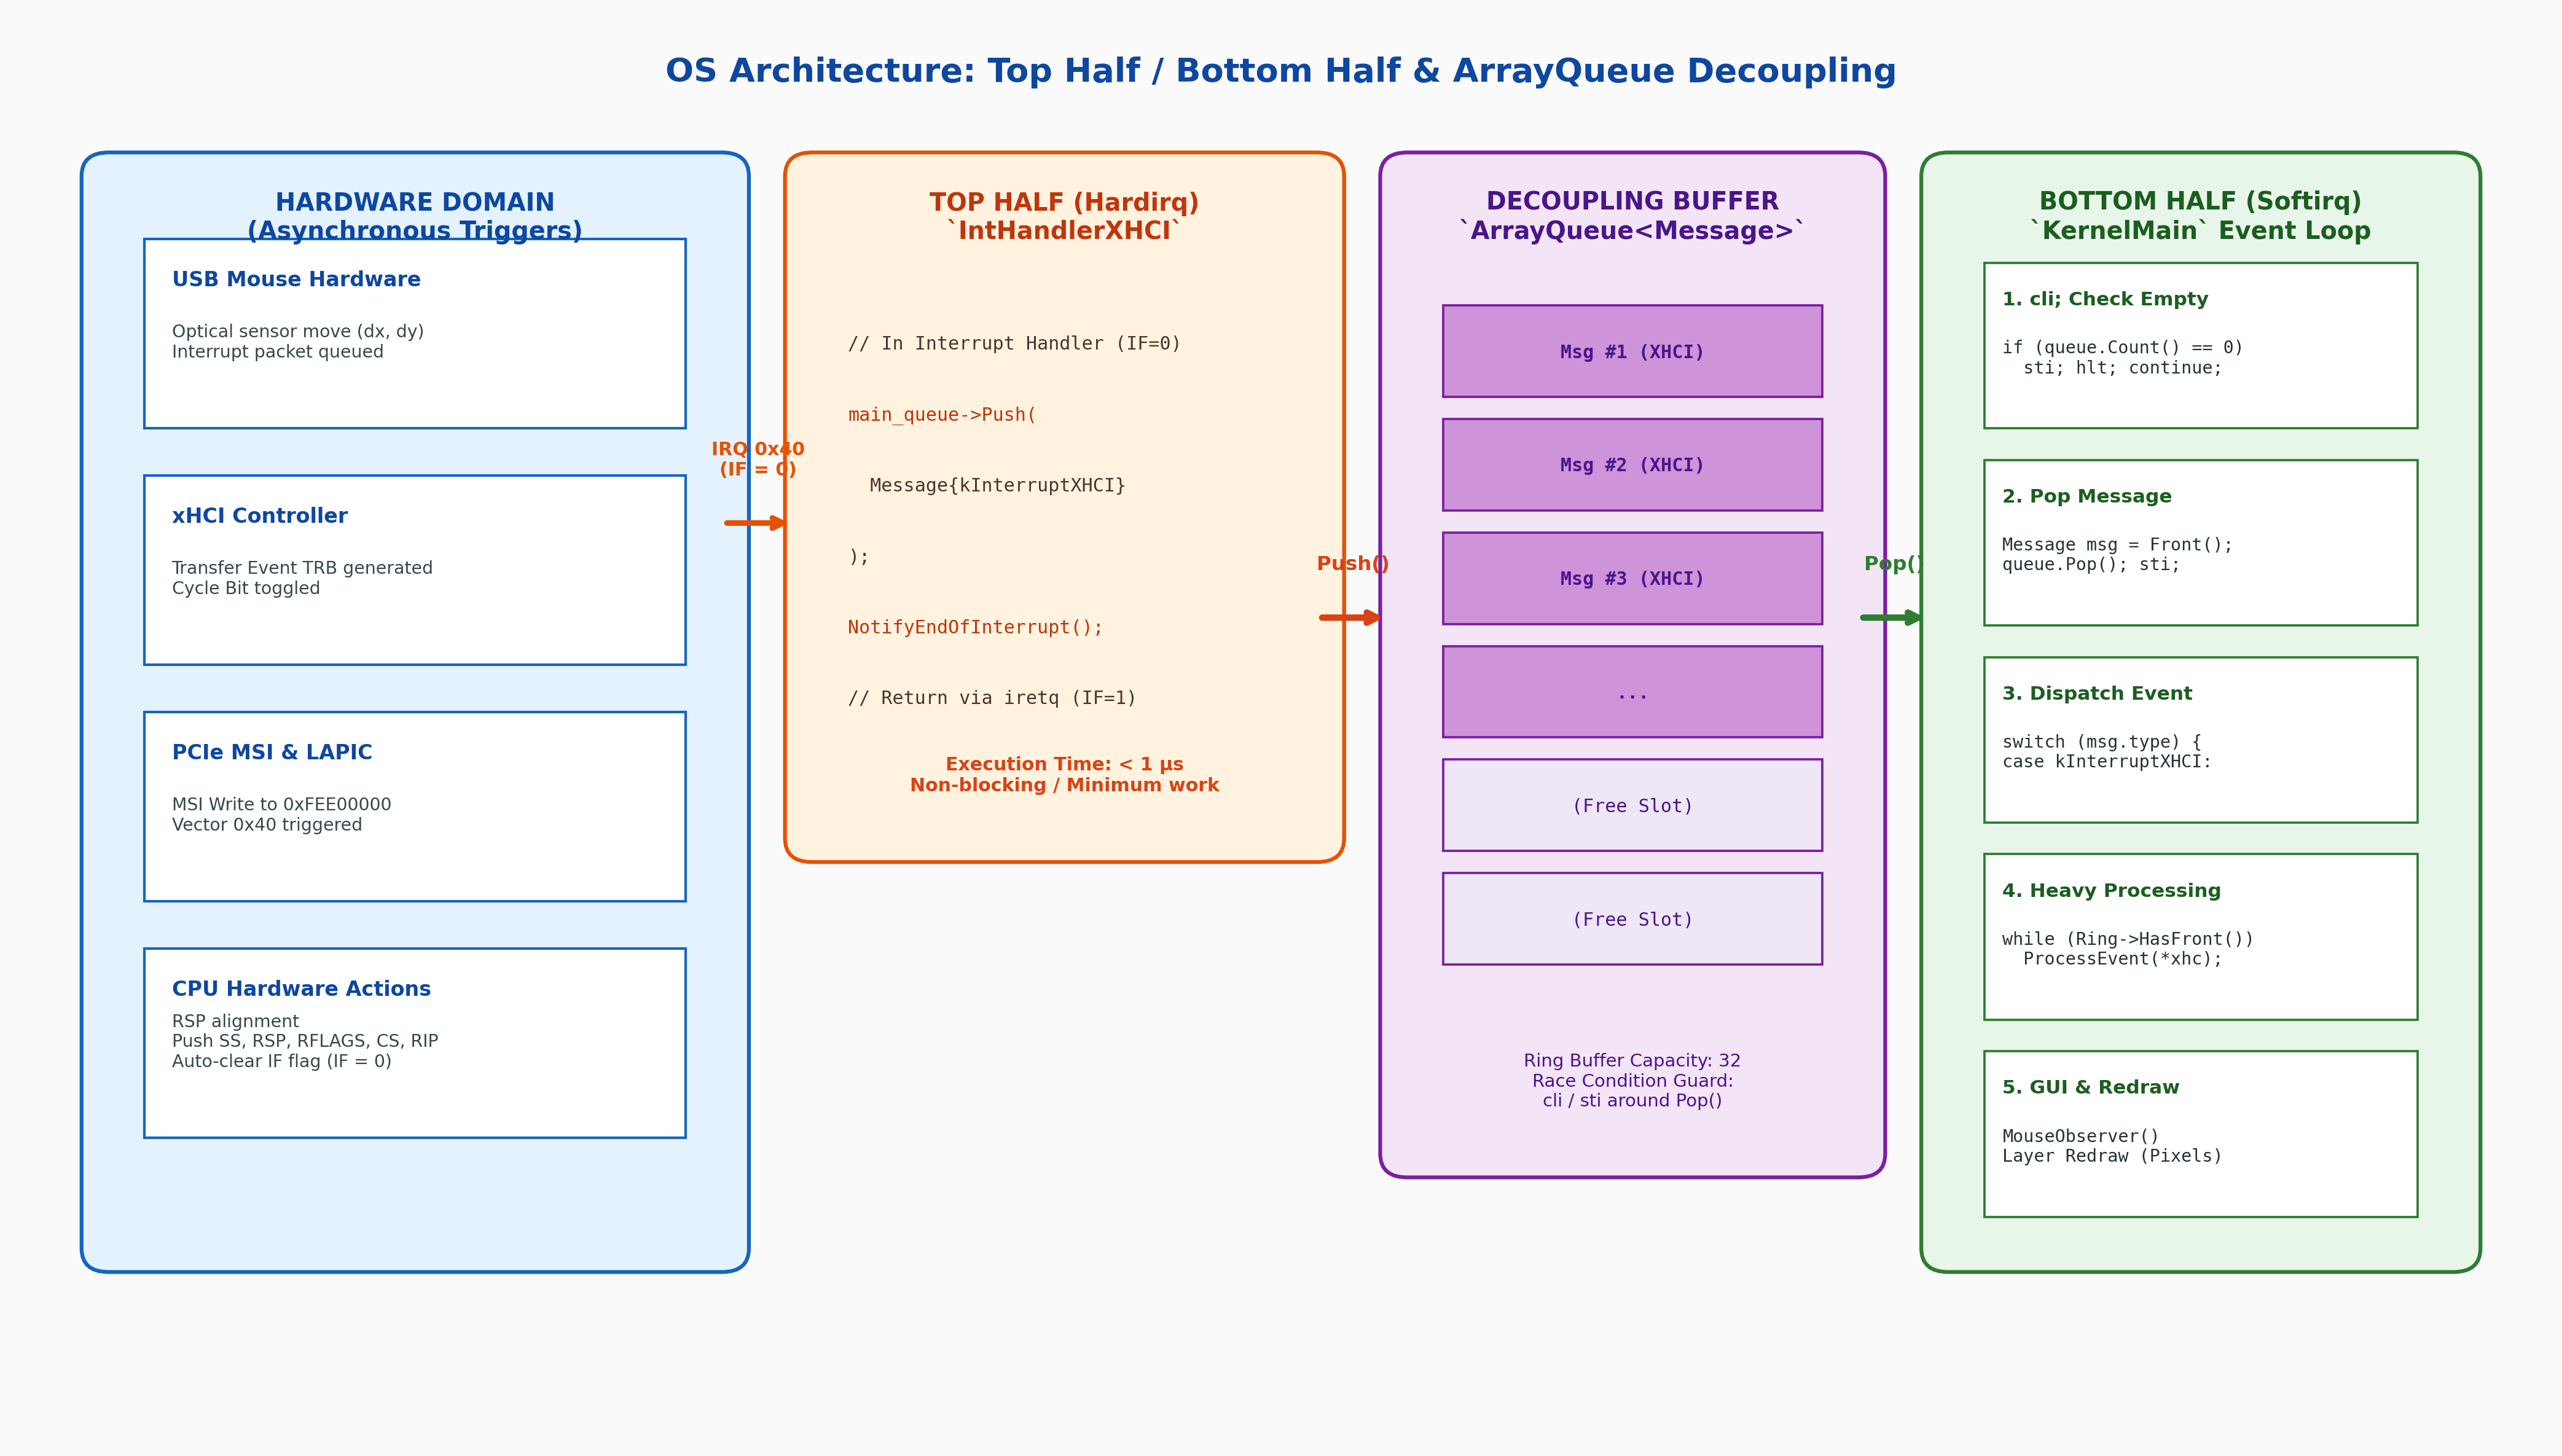

In [3]:
from common import plot_top_half_bottom_half_architecture

fig_arch = plot_top_half_bottom_half_architecture("7/result/fig7_14_top_half_bottom_half_architecture_and_queue.png")
print("✅ アーキテクチャ図生成完了:", fig_arch)
display(Image(fig_arch))


## 7.7.3 MikanOS における実装差分 (`osbook_day07a` $\to` `osbook_day07b`)

公式リポジトリ（`vendor/mikanos`）における `osbook_day07a` から `osbook_day07b` への変更点を確認します。

### 1. メッセージ構造体 `Message` の定義 (`kernel/main.cpp`)

イベントの種類を表す `enum Type` を持つ軽量構造体 `Message` を定義します。

```cpp
// kernel/main.cpp (osbook_day07b)
struct Message {
  enum Type {
    kInterruptXHCI,
  } type;
};

ArrayQueue<Message>* main_queue;
```

将来の章では、タイマタイムアウト（`kTimerTimeout`）やキーボード入力（`kKeyInput`）など、あらゆる非同期イベントがこの `Message` に統合されていきます。


### 2. 劇的にスリム化した割り込みハンドラ (`IntHandlerXHCI`)

前節では 10 行以上あった重い処理が、**わずか 2 行**に圧縮されます：

```cpp
// kernel/main.cpp (osbook_day07b)
__attribute__((interrupt))
void IntHandlerXHCI(InterruptFrame* frame) {
  main_queue->Push(Message{Message::kInterruptXHCI});
  NotifyEndOfInterrupt();
}
```

- `main_queue->Push(...)`: イベント発生をキューに登録するだけ（約 30〜50 クロックサイクル）。
- `NotifyEndOfInterrupt()`: Local APIC に EOI を通知。
- コンパイラ生成のエピローグを経て直ちに `iretq` で復帰。

---

### 3. メインループによる遅延処理 (`KernelMain`)

割り込みハンドラから追放された `ProcessEvent` は、`KernelMain` の末尾にあるメインイベントループへ移譲されます：

```cpp
// kernel/main.cpp (osbook_day07b)
while (true) {
  __asm__("cli");
  if (main_queue.Count() == 0) {
    __asm__("sti\n\thlt");
    continue;
  }

  Message msg = main_queue.Front();
  main_queue.Pop();
  __asm__("sti");

  switch (msg.type) {
  case Message::kInterruptXHCI:
    while (xhc.PrimaryEventRing()->HasFront()) {
      if (auto err = ProcessEvent(xhc)) {
        Log(kError, "Error while ProcessEvent: %s at %s:%d\n",
            err.Name(), err.File(), err.Line());
      }
    }
    break;
  default:
    Log(kError, "Unknown message type: %d\n", msg.type);
  }
}
```

> [!NOTE]
> `__asm__("cli")` と `__asm__("sti")` で `main_queue` の操作を挟んでいる点に注目してください。
> メインループがキューを操作（読み出し・ポインタ更新）している最中に Top Half 割り込みが発生して `Push()` されると、キューの内部変数（`read_pos_`, `write_pos_`, `count_`）が破壊される**競合状態（*Race Condition*）** が発生します。
> これを防ぐための排他制御については、第7章の後半（7.10節）でさらに深く掘り下げます。


In [4]:
# === Python による ArrayQueue（リングバッファ）の対話型シミュレーション ===
class InteractiveArrayQueue:
    def __init__(self, capacity: int):
        self.capacity = capacity
        self.buffer = [None] * capacity
        self.read_pos = 0
        self.write_pos = 0
        self.count = 0

    def push(self, val):
        if self.count == self.capacity:
            return False, "Error::kFull"
        self.buffer[self.write_pos] = val
        self.write_pos = (self.write_pos + 1) % self.capacity
        self.count += 1
        return True, "Success"

    def pop(self):
        if self.count == 0:
            return None, "Error::kEmpty"
        val = self.buffer[self.read_pos]
        self.read_pos = (self.read_pos + 1) % self.capacity
        self.count -= 1
        return val, "Success"

    def dump_state(self):
        return f"[Count: {self.count}/{self.capacity}, Read: {self.read_pos}, Write: {self.write_pos}] Buf: {self.buffer}"

# デモ実行
q = InteractiveArrayQueue(4)
print("初期状態:", q.dump_state())

for i in range(4):
    ok, err = q.push(f"Msg_{i}")
    print(f"Push Msg_{i} ->", q.dump_state())

# 5個目の Push は満杯で失敗
ok, err = q.push("Msg_Overflow")
print("満杯時の Push ->", err, q.dump_state())

# 2個 Pop してリングバッファの循環（ラップアラウンド）を確認
v1, _ = q.pop()
v2, _ = q.pop()
print(f"Pop 2件 ({v1}, {v2}) ->", q.dump_state())

# さらに Push して write_pos が 0 に循環することを確認
q.push("Msg_4_Wrapped")
print("ラップアラウンド Push ->", q.dump_state())


初期状態: [Count: 0/4, Read: 0, Write: 0] Buf: [None, None, None, None]
Push Msg_0 -> [Count: 1/4, Read: 0, Write: 1] Buf: ['Msg_0', None, None, None]
Push Msg_1 -> [Count: 2/4, Read: 0, Write: 2] Buf: ['Msg_0', 'Msg_1', None, None]
Push Msg_2 -> [Count: 3/4, Read: 0, Write: 3] Buf: ['Msg_0', 'Msg_1', 'Msg_2', None]
Push Msg_3 -> [Count: 4/4, Read: 0, Write: 0] Buf: ['Msg_0', 'Msg_1', 'Msg_2', 'Msg_3']
満杯時の Push -> Error::kFull [Count: 4/4, Read: 0, Write: 0] Buf: ['Msg_0', 'Msg_1', 'Msg_2', 'Msg_3']
Pop 2件 (Msg_0, Msg_1) -> [Count: 2/4, Read: 2, Write: 0] Buf: ['Msg_0', 'Msg_1', 'Msg_2', 'Msg_3']
ラップアラウンド Push -> [Count: 3/4, Read: 2, Write: 1] Buf: ['Msg_4_Wrapped', 'Msg_1', 'Msg_2', 'Msg_3']


In [5]:
# === C++20 スタンドアロン検証コードのコンパイルと実行 ===
import subprocess

compile_cmd = [
    "g++", "-std=c++20", "-O2", "-Wall", "-Wextra", "-pedantic",
    "src/ch07/fast_interrupt_sim.cpp",
    "-o", "build/bin/ch07_fast_interrupt_sim"
]
print("🔨 コンパイル実行:", " ".join(compile_cmd))
c_res = subprocess.run(compile_cmd, capture_output=True, text=True)
if c_res.returncode != 0:
    print("❌ コンパイルエラー:\n", c_res.stderr)
else:
    print("✅ コンパイル成功！実行中...\n")
    run_res = subprocess.run(["build/bin/ch07_fast_interrupt_sim"], capture_output=True, text=True)
    print(run_res.stdout)


🔨 コンパイル実行: g++ -std=c++20 -O2 -Wall -Wextra -pedantic src/ch07/fast_interrupt_sim.cpp -o build/bin/ch07_fast_interrupt_sim


✅ コンパイル成功！実行中...

 MikanOS Chapter 7.7: Fast Interrupt Handling Simulation
 Top Half / Bottom Half Decoupling & ArrayQueue Verification

[Test 1/4] Verifying ArrayQueue ring buffer invariants...
  -> ArrayQueue ring buffer wrap-around, full/empty guards PASSED.
[Test 2/4] Verifying Monolithic handler bottleneck and drops...
  Monolithic Stats: Dropped = 6 / 10, Max Latency = 186 us
  -> Monolithic handler bottleneck and packet drops confirmed.
[Test 3/4] Verifying Split Top/Bottom Half zero drops and low latency...
  Split Stats: Dropped = 0 / 10, Max Top-Half Latency = 0 us, Max Hold Time = 0.8 us
  -> Split Top/Bottom Half zero drops & sub-microsecond latency confirmed.
[Test 4/4] Quantitative comparison under intense 50-event burst...

  PERFORMANCE COMPARISON SUMMARY (50-event Burst Simulation)
Metric                      Monolithic (day07a) Split (day07b)      
--------------------------------------------------------------------
Processed Events            12                  50  

## 7.7.4 数理モデル導出：到着率・サービス率と割り込み遅延

ここでは、オペレーティングシステムと情報ネットワーク工学における **待ち行列理論（*Queueing Theory*）** を用いて、モノリシック方式と分割方式の挙動差を数理的に導出・証明します。

### 1. パラメータの定義

- イベント到着率: $\lambda$ [events / sec] (平均到着間隔 $1 / \lambda$)
- モノリシックハンドラの処理時間: $T_{\text{mono}} = T_{\text{draw}} + T_{\text{overhead}}$
  - モノリシックサービス率: $\mu_{\text{mono}} = \frac{1}{T_{\text{mono}}}$
- 分割型 Top Half の処理時間: $T_{\text{top}} = T_{\text{push}} + T_{\text{eoi}}$
  - Top Half サービス率: $\mu_{\text{top}} = \frac{1}{T_{\text{top}}}$
- 分割型 Bottom Half の処理時間: $T_{\text{bottom}} = T_{\text{draw}}$


### 2. 安定性の条件（*Stability Condition*）とパケット破棄率

M/M/1 または M/D/1 待ち行列において、システムが無限に発散（キュー溢れ・パケットドロップ）しないための必要十分条件は、利用率 $\rho < 1$ です：

$$\rho = \frac{\lambda}{\mu} < 1 \iff \lambda < \mu$$

- **モノリシック方式の場合**:
  ピクセル描画に $T_{\text{mono}} = 100\,\mu\text{s}$ かかるとすると、最大処理能力は：
  $$\mu_{\text{mono}} = \frac{1}{100 \times 10^{-6}\,\text{s}} = 10{,}000\,\text{events/sec}$$
  もしマウスの高速操作や他デバイスのバーストで瞬間到着率が $\lambda = 15{,}000\,\text{events/sec}$ に達すると、$\rho = 1.5 > 1$ となり**ハードウェアバッファは瞬時に破綻し、破棄率 $P_{\text{drop}} = 1 - \frac{1}{\rho} = 33.3\%$ でパケットが喪失**します。

- **分割型 Top Half の場合**:
  Top Half は単にキューへ Push するだけなので $T_{\text{top}} = 0.5\,\mu\text{s}$ です：
  $$\mu_{\text{top}} = \frac{1}{0.5 \times 10^{-6}\,\text{s}} = 2{,}000{,}000\,\text{events/sec}$$
  利用率は $\rho_{\text{top}} = \frac{15{,}000}{2{,}000{,}000} = 0.0075 \ll 1$ であり、**ハードウェア割り込みに対して圧倒的な余力（99% 以上の余裕）** を持ちます。

---

### 3. 平均割り込み待ち時間 $W_q$

ポラック・ヒンチンの公式（*Pollaczek-Khinchine Formula*）より、平均待ち時間 $W_q$ は以下で与えられます：

$$W_q = \frac{\lambda \cdot \mathbb{E}[S^2]}{2(1 - \rho)}$$

Top Half の処理時間分散および平均時間はモノリシック方式に比べて数百分の一であるため、**ハードウェア割り込み遅延は文字通り桁違いに極小化**されます。


✅ 数理モデル比較プロット生成完了: 7/result/fig7_15_queueing_latency_and_drop_analysis.png


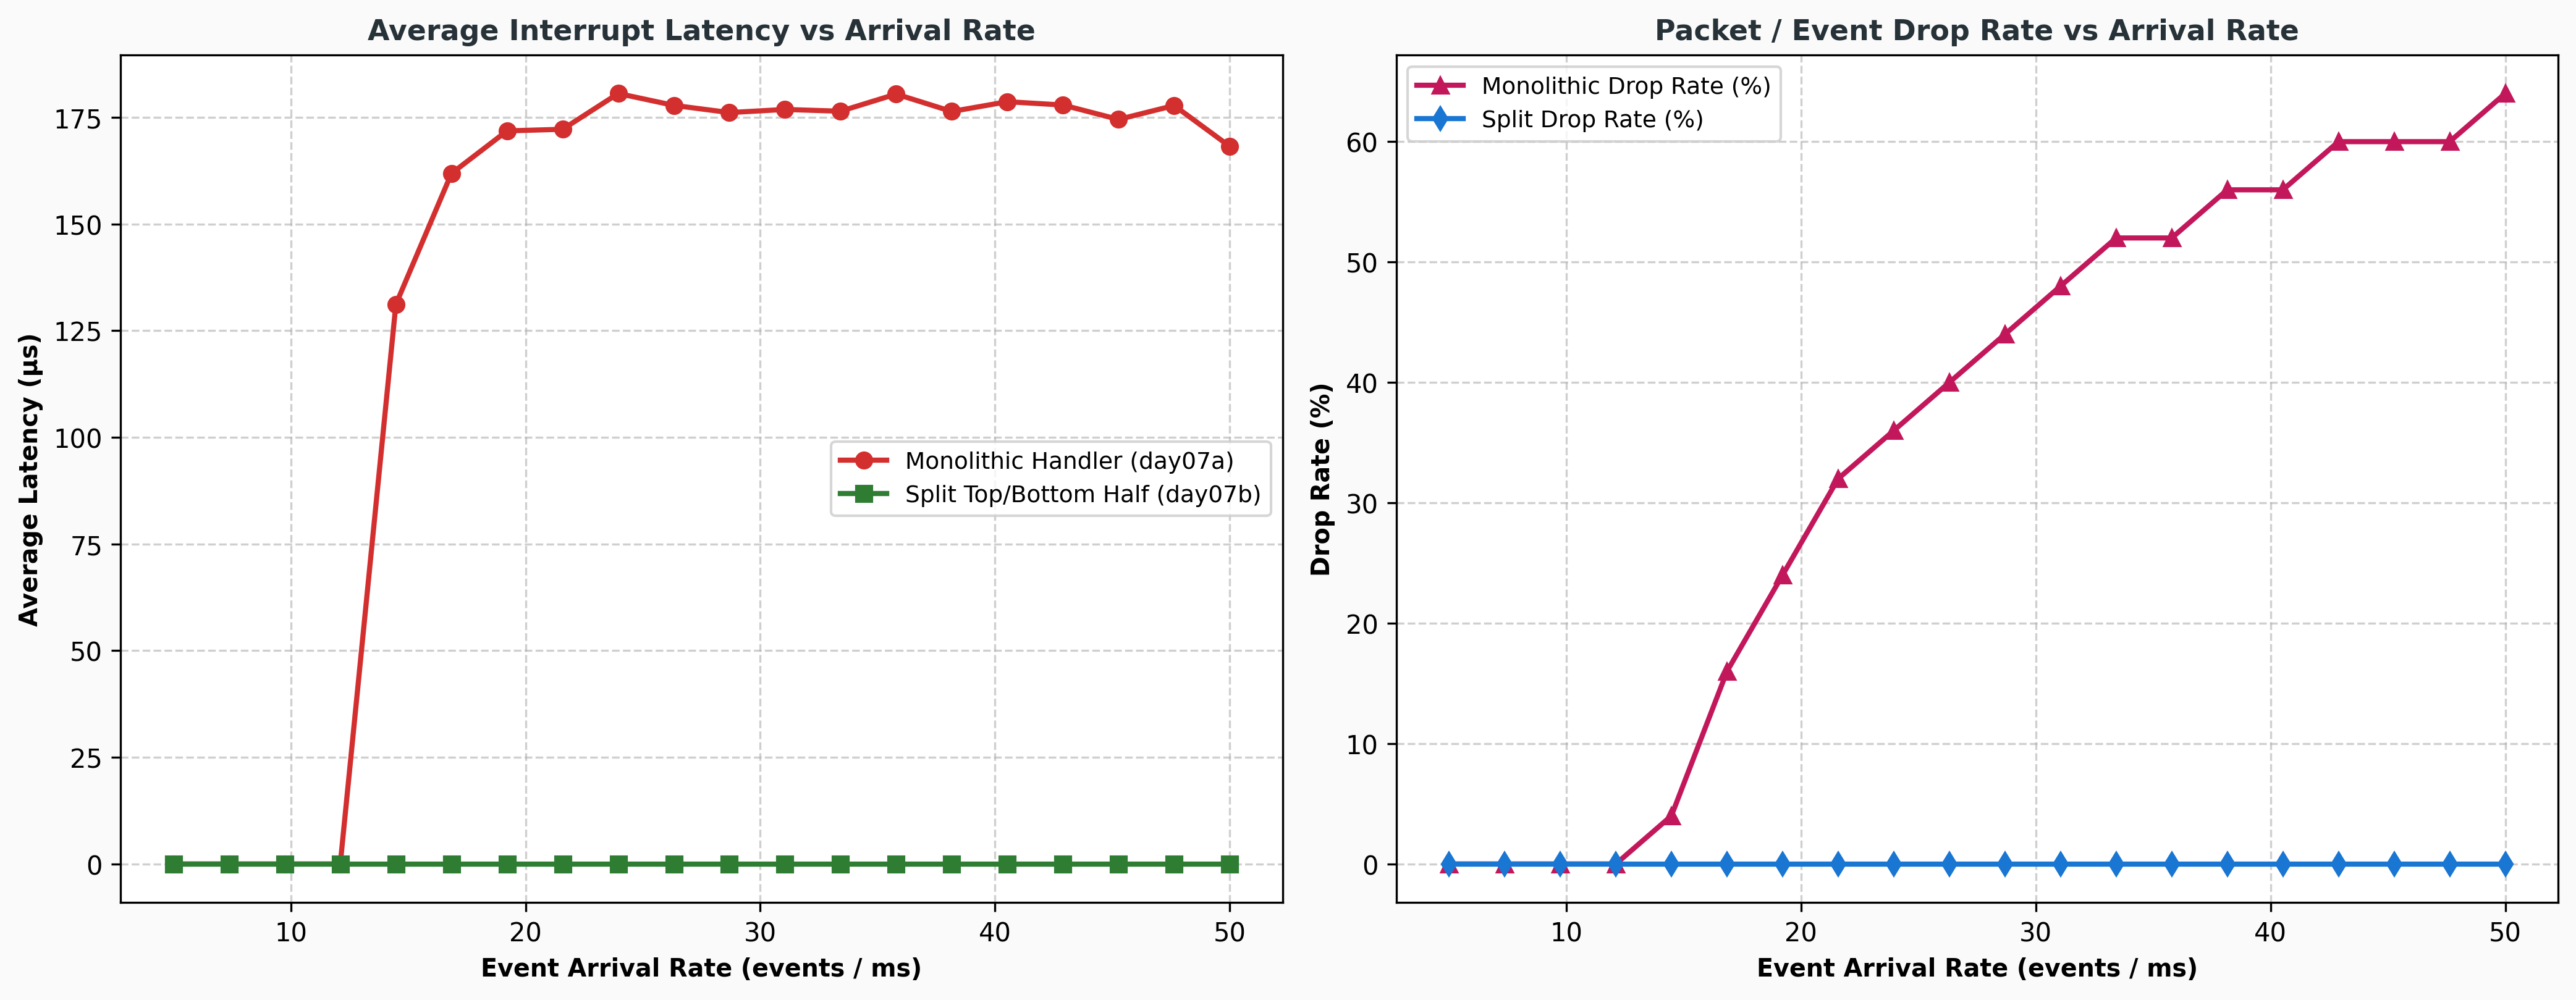

In [6]:
from common import plot_queueing_latency_model

fig_model = plot_queueing_latency_model("7/result/fig7_15_queueing_latency_and_drop_analysis.png")
print("✅ 数理モデル比較プロット生成完了:", fig_model)
display(Image(fig_model))


---

### 💡 コラム 7.2: Linux カーネルにおけるボトムハーフの変遷と MikanOS の選択

Linux カーネルの歴史は、まさに「いかにボトムハーフを洗練させるか」の進化の歴史でもありました。

1. **初代 `bottom_half` (Linux 1.x)**:
   最大 32 個の固定関数ポインタ配列。システム全体で同時に 1 つのボトムハーフしか走れず、マルチコア（SMP）時代に致命的なボトルネックとなった。
2. **`tasklet` と `softirq` (Linux 2.3〜)**:
   SMP に対応した高スループットなボトムハーフ。`softirq` は同じハンドラが複数 CPU で並行動作可能（ネットワーク等向け）、`tasklet` は同一インスタンスの排他を自動保証（ドライバ向け）。
3. **`workqueue` (Linux 2.6〜)**:
   カーネルスレッド（プロセスコンテキスト）上で遅延処理を行う機構。割り込みコンテキストと異なり、処理の途中でスリープ（`msleep` やミューテックス待機）が可能。
4. **Threaded IRQ (リアルタイム Linux / 現行カーネル)**:
   割り込みハンドラ自体を専用のカーネルスレッドとして起床させ、スケジューラの管理下に置くことでリアルタイム性を向上。

#### MikanOS が選んだアーキテクチャ
MikanOS では、複雑なカーネルスレッド機構を導入する前の現段階において、**「固定サイズ配列によるリングバッファ（`ArrayQueue`）＋メインループ（`KernelMain`）でのディスパッチ」** という極めて直感的かつオーバーヘッドゼロの設計を採用しています。
このシンプルさこそが、OS の基礎概念（イベント駆動・非同期メッセージング）を最も透明性高く学ぶための最良の教材構造となっています。


---

## 7.7.5 理解度セルフチェック（全3問）

以下の問題を考えた上で、各カードをクリックして解説を展開してください。

<details>
<summary><b>Q1. x86-64 の Interrupt Gate でハンドラ突入時に IF フラグが 0 になる理由と、その状態でピクセル描画を行うと生じる問題は何ですか？</b></summary>

**【解答】**
1. **IF が 0 になる理由**:
   割り込み処理中に同じ、あるいは別の割り込みが再突入することによるスタックオーバーフローやカーネル内部データ構造の破壊（多重割り込みによる競合）をハードウェアレベルで防ぐため。
2. **ピクセル描画を行うと生じる問題**:
   ピクセル描画は数万〜数十万サイクルを要するため、その長期間にわたって CPU 全体の割り込みがマスク（無効化）されます。その結果、タイマ割り込みの取りこぼしによる時刻の狂い、キーボードやネットワークパケットの受信遅延、およびハードウェアバッファ溢れによるイベントドロップ（マウスカーソルのカクつき）が発生します。
</details>

<br>

<details>
<summary><b>Q2. Top Half（Hardirq）と Bottom Half（Softirq / イベントループ）の決定的な違いを、実行時の「IF フラグの状態」と「許容される処理時間」の観点から説明してください。</b></summary>

**【解答】**
- **Top Half (Hardirq)**:
  - **IF フラグ**: `0`（割り込み禁止状態）
  - **許容処理時間**: 数ナノ秒〜1マイクロ秒未満（極小）
  - **役割**: ハードウェアの最小限の確認、キューへの Push、EOI 通知のみを行い即座に復帰する。
- **Bottom Half (Softirq / イベントループ)**:
  - **IF フラグ**: `1`（割り込み許可状態）
  - **許容処理時間**: 制限なし（必要に応じて数ミリ秒〜数十ミリ秒かけてよい）
  - **役割**: キューからイベントを取り出し、デバイス解析や画面描画など負荷の高い処理を実行する。実行中であっても新たなハードウェア割り込みによるプリエンプションを受け付ける。
</details>

<br>

<details>
<summary><b>Q3. MikanOS の `KernelMain` イベントループで `main_queue.Pop()` を行う前後に `cli` と `sti` が挟まれているのはなぜですか？</b></summary>

**【解答】**
メインループ（Bottom Half）が `ArrayQueue` の要素を取り出す際、`read_pos_` や `count_` などの内部変数を更新します。もしこの更新処理の最中にハードウェア割り込みが発生して Top Half ハンドラが起動し、`main_queue->Push()` を呼んで `write_pos_` や `count_` を更新すると、キューのインデックスや要素数が不正な値に破壊される**競合状態（Race Condition）** が発生します。
これを防ぐため、キューの検査・読み出し区間を `cli`（割り込み禁止）と `sti`（割り込み許可）で保護（クリティカルセクション化）しています。
</details>


---

## 7.7.6 次節への展望：キュー構造の数理と実装

本節では、モノリシックハンドラの課題を解決するために「イベントをキューに預けてメインループで遅延処理する」という Top Half / Bottom Half アーキテクチャの動機と全体像を確立しました。

次節 **「7.8 FIFOとFILO」** および **「7.9 キューの実装」** では：
- なぜスタック（FILO / LIFO）ではなくキュー（FIFO）でなければならないのか？
- メモリ割り当て（`malloc` / `new`）がまだ存在しないベアメタル OS カーネル環境において、固定長配列上で循環ポインタを用いたリングバッファ `ArrayQueue<T>` をいかに実装するか？
- ポインタのラップアラウンド（循環）、満杯（Full）と空（Empty）の厳密な判定条件

をステップ・バイ・ステップで導出・実装していきます。
